# XGBoost + price-minus-water-value features

Extends `xgboost_baseline.ipynb` (hold-out 2022 micro AUC **0.8623**) with one physically motivated feature group.

**Idea.** A hydropower unit is worth running in an hour when the electricity price exceeds the marginal value of
the water it would use. The water value of the reservoir directly upstream of each plant is in the dataset, so
for each plant we add

- `margin_<plant>`      = price at hour *t* − water value of its upstream reservoir at case start
- `margin_end_<plant>`  = price at hour *t* − water value of its upstream reservoir at case end (start + 7 days)
- `margin_end_wk_<plant>` = week-mean price − end water value (how attractive the whole week is)

The plant → reservoir mapping comes from the `connections` section of `data/extended/Tokke_Vinje_topology.yaml`.
**Validation protocol (fixed after the leakage audit).** The number of boosting rounds is chosen by early stopping
on 2021 (training on cases before 2021). The reported score then comes from a model trained on cases before 2022 and
scored on 2022, so the reported year never influences a modelling decision. A one-week gap keeps the overlapping
cases of late December out of the training set. The baseline, re-run under this protocol, is the reference.

### Shared code

Data loading, feature construction and the honest validation protocol. The same code is repeated at the top of every notebook so each one runs on its own.

In [ ]:
from pathlib import Path
from sklearn.metrics import roc_auc_score
import json
import numpy as np
import pandas as pd
import re
import time
import xgboost as xgb

# ---- formerly src/train_xgb_baseline.py ----
# XGBoost baseline for the SINTEF unit-commitment task.
#
# Script version of xgboost_baseline.ipynb so it can run headless on the GPU desktop.
#
# Validation protocol: rounds are chosen by early stopping on 2021 (training on cases before 2021);
# the reported score is then from a model trained on cases before 2022 and scored on 2022, so the
# reported year never influences a modelling decision. A one-week gap keeps overlapping cases apart.
#
#     py train_xgb_baseline.py --device cuda          # GPU
#     python train_xgb_baseline.py --device cpu       # laptop
#
# Outputs (in --out, default ./results):
#     submission_xgb_baseline.csv   Kaggle submission (test cases 2023-2024)
#     val_pred_2022.npy             hold-out probabilities, shape (365*168, 14)
#     metrics.json                  hold-out micro AUC, per-unit AUC, best iteration, timings
#     feature_importance.csv        gain per feature (summed over the 14 boosters)

H = 168
SEED = 42

def load(data_dir):
    data_dir = Path(data_dir)
    uc = pd.read_csv(
        data_dir / "Unit_commitment_decisions.csv", parse_dates=["starttime"]
    )
    price = (
        pd.read_csv(
            data_dir / "Historical_day_ahead_price_2015_2025.csv", parse_dates=["date"]
        )
        .set_index("date")["Day-ahead price (EUR/MWh)"]
        .resample("h")
        .mean()
    )
    inflow = pd.read_csv(
        data_dir / "Historical_inflow_1958_2025.csv", parse_dates=["date"]
    ).set_index("date")
    inflow = inflow[inflow.index >= "2014-12-01"].resample("h").mean()
    volume = pd.read_csv(
        data_dir / "Historical_volume_2015_2024.csv", parse_dates=["date"]
    ).set_index("date")
    water_value = pd.read_csv(
        data_dir / "Synthetic_water_value_2015_2024.csv", parse_dates=["date"]
    ).set_index("date")
    return uc, price, inflow, volume, water_value

class FeatureBuilder:
    def __init__(self, price, inflow, volume, water_value):
        self.price, self.inflow, self.volume, self.wv = (
            price,
            inflow,
            volume,
            water_value,
        )

    @staticmethod
    def window(hourly_df, starts, horizon=H):
        idx = hourly_df.index.get_indexer(starts)
        assert (idx >= 0).all(), (
            "some case start times are missing from the hourly series"
        )
        pos = idx[:, None] + np.arange(horizon)[None, :]
        return hourly_df.to_numpy(dtype=np.float32)[pos]

    def __call__(self, starts):
        starts = pd.DatetimeIndex(starts)
        if starts.tz is None:
            starts = starts.tz_localize("UTC")
        n = len(starts)
        P = self.window(self.price.to_frame(), starts)[:, :, 0]
        I = self.window(self.inflow, starts)
        V = self.volume.reindex(starts).to_numpy(dtype=np.float32)
        W = self.wv.reindex(starts).to_numpy(dtype=np.float32)
        W_end = self.wv.reindex(starts + pd.Timedelta(days=7)).to_numpy(
            dtype=np.float32
        )
        hours = pd.DatetimeIndex(
            (
                starts.values[:, None] + np.arange(H)[None, :] * np.timedelta64(1, "h")
            ).ravel()
        )
        rep = lambda a: np.repeat(a, H)

        f = pd.DataFrame(
            {
                "t": np.tile(np.arange(H), n),
                "hour": hours.hour,
                "dow": hours.dayofweek,
                "month": hours.month,
                "doy": hours.dayofyear,
                "price": P.ravel(),
                "price_week_mean": rep(P.mean(1)),
                "price_week_std": rep(P.std(1)),
                "price_week_min": rep(P.min(1)),
                "price_week_max": rep(P.max(1)),
            }
        )
        f["price_rel"] = f["price"] - f["price_week_mean"]
        f["price_rank"] = (P.argsort(1).argsort(1) / (H - 1)).ravel()
        f["price_day_mean"] = np.repeat(P.reshape(n, 7, 24).mean(2), 24, axis=1).ravel()
        f["price_prev"] = np.concatenate([P[:, :1], P[:, :-1]], axis=1).ravel()   # edge-padded, no wrap
        f["price_next"] = np.concatenate([P[:, 1:], P[:, -1:]], axis=1).ravel()
        for j, c in enumerate(self.inflow.columns):
            f[f"inflow_{c}"] = I[:, :, j].ravel()
        f["inflow_total"] = I.sum(2).ravel()
        for j, c in enumerate(self.volume.columns):
            f[f"vol_{c}"] = rep(V[:, j])
        for j, c in enumerate(self.wv.columns):
            f[f"wv_{c}"] = rep(W[:, j])
        for j, c in enumerate(self.wv.columns):
            f[f"wv_end_{c}"] = rep(W_end[:, j])
        return f

def split_masks(starts, val_year, gap_days=7):
    """Case-level masks. train: cases whose whole week ends before val_year (so no hour is shared with the
    validation cases); val: cases starting in val_year. Returned per case, use np.repeat(mask, H) for rows."""
    starts = pd.DatetimeIndex(starts)
    val_start = pd.Timestamp(f"{val_year}-01-01")
    train = np.asarray(starts < val_start - pd.Timedelta(days=gap_days - 1))
    val = np.asarray(starts.year == val_year)
    return train, val

def honest_fit(X, Y, starts, params, tune_year=2021, report_year=2022, device="cuda", verbose=False, max_rounds=3000):
    """Two-stage validation so the reported year is never used to make a modelling decision.

    stage 1: train on cases before tune_year, early-stop on tune_year  -> number of rounds
    stage 2: train on cases before report_year with that many rounds   -> score on report_year
    Returns a dict with n_rounds, tune_auc, report_auc, per-unit AUC, the stage-2 model and its predictions.
    """
    common = dict(tree_method="hist", device=device, random_state=SEED, **params)
    tr1, va1 = (np.repeat(m, H) for m in split_masks(starts, tune_year))
    m1 = xgb.XGBClassifier(n_estimators=max_rounds, eval_metric="auc", early_stopping_rounds=100, **common)
    m1.fit(X[tr1], Y[tr1], eval_set=[(X[va1], Y[va1])], verbose=verbose)
    n_rounds = int(m1.best_iteration) + 1
    tune_auc = roc_auc_score(Y[va1], m1.predict_proba(X[va1]), average="micro")

    tr2, va2 = (np.repeat(m, H) for m in split_masks(starts, report_year))
    m2 = xgb.XGBClassifier(n_estimators=n_rounds, **common).fit(X[tr2], Y[tr2])
    pred = m2.predict_proba(X[va2])
    report_auc = roc_auc_score(Y[va2], pred, average="micro")   # identical to kaggle_metric.score
    per_unit = [roc_auc_score(Y[va2][:, j], pred[:, j]) for j in range(Y.shape[1])]
    return dict(n_rounds=n_rounds, tune_auc=float(tune_auc), report_auc=float(report_auc),
                per_unit=per_unit, model=m2, pred=pred, val_mask=va2)


In [1]:
# run from the repo root so that data/ and results/ resolve (notebooks live in notebooks/)
import os, sys
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
from sklearn.metrics import roc_auc_score

from kaggle_metric import score

SEED = 42
BASELINE_AUC = None   # filled from results/metrics_baseline_honest.json if present (baseline re-run under this protocol)

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "figure.dpi": 110})
BLUE = "#2a78d6"

def pick_device():
    try:
        xgb.XGBClassifier(n_estimators=1, device="cuda").fit(np.zeros((4, 1)), [0, 1, 0, 1])
        return "cuda"
    except Exception:
        return "cpu"

DEVICE = pick_device()
print("training device:", DEVICE)

training device: cuda


## 1. Load data and baseline features

In [2]:
uc, price, inflow, volume, water_value = load("data/kernel")
test_map = pd.read_csv("prediction_mapping.csv", parse_dates=["starttime"])
sample = pd.read_csv("sample_submission.csv", nrows=1)

label_cols = [c for c in sample.columns if c != "Run No"]
assert label_cols == [c for c in uc.columns if c.startswith("result_committed_")]
units = list(dict.fromkeys(c.rsplit("_t", 1)[0].replace("result_committed_", "") for c in label_cols))
N_UNITS = len(units)

build_base = FeatureBuilder(price, inflow, volume, water_value)

def build_targets(uc_df):
    Y = uc_df[label_cols].to_numpy(dtype=np.int8).reshape(len(uc_df), N_UNITS, H)
    return Y.transpose(0, 2, 1).reshape(-1, N_UNITS)

def to_wide(pred_long, run_ids):
    wide = pred_long.reshape(len(run_ids), H, N_UNITS).transpose(0, 2, 1).reshape(len(run_ids), -1)
    out = pd.DataFrame(wide, columns=label_cols)
    out.insert(0, "Run No", np.asarray(run_ids))
    return out

print(f"{len(uc)} train cases, {len(test_map)} test cases, {N_UNITS} units")

2922 train cases, 725 test cases, 14 units


## 2. Plant → upstream reservoir

Read from the `connections` list in `Tokke_Vinje_topology.yaml` (entries with `from_type: reservoir`, `to_type: plant`).
Songa is fed by two tunnels; Songavatn (order 0) is the main one.

In [3]:
UPSTREAM = {
    "Hogga": "Bandak",
    "Tokke": "Vinjevatn",
    "Lio": "Byrtevatn",
    "Byrte": "Botnedalsvatn",
    "Vinje": "Vaamarvatn",
    "Haukeli": "Vatjern",
    "Songa": "Songavatn",
    "Kjela": "Foersvatn",
    "Vesle Kjela": "Kjelavatn",
}
assert set(UPSTREAM.values()) <= set(water_value.columns)
assert {u.rsplit("_G", 1)[0] for u in units} == set(UPSTREAM)

def add_margin_features(f):
    """price − water value of the upstream reservoir, per plant. f is a baseline feature frame."""
    f = f.copy()
    for plant, res in UPSTREAM.items():
        f[f"margin_{plant}"] = f["price"] - f[f"wv_{res}"]
        f[f"margin_end_{plant}"] = f["price"] - f[f"wv_end_{res}"]
        f[f"margin_end_wk_{plant}"] = f["price_week_mean"] - f[f"wv_end_{res}"]
    return f

t0 = time.time()
X = add_margin_features(build_base(uc["starttime"]))
Y = build_targets(uc)
case_year = np.repeat(uc["starttime"].dt.year.to_numpy(), H)
new_cols = [c for c in X.columns if c.startswith("margin")]
print(f"X: {X.shape} ({len(new_cols)} new margin features), built in {time.time() - t0:.1f}s")
X[["t", "price", "wv_Vinjevatn", "margin_Tokke", "wv_end_Vinjevatn", "margin_end_Tokke"]].head()

X: (490896, 112) (27 new margin features), built in 0.5s


,t,price,wv_Vinjevatn,margin_Tokke,wv_end_Vinjevatn,margin_end_Tokke
0,0,27.070000,22.65,4.420000,19.65,7.420000
1,1,26.930000,22.65,4.280001,19.65,7.280001
2,2,26.830000,22.65,4.180000,19.65,7.180000
3,3,26.809999,22.65,4.160000,19.65,7.160000
4,4,26.969999,22.65,4.320000,19.65,7.320000


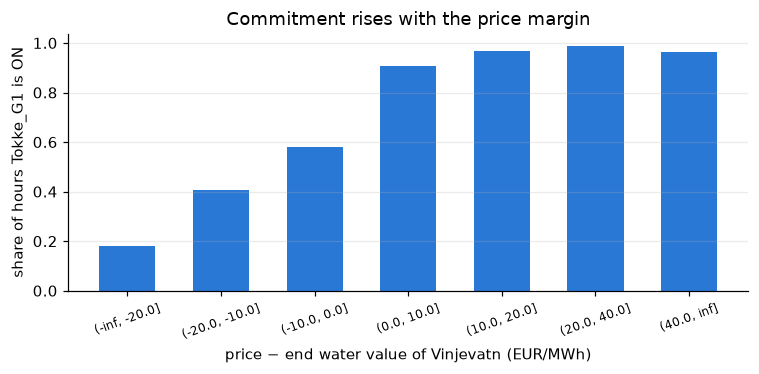

In [4]:
# sanity check: is Tokke more often ON when the price beats its water value?
m = X["margin_end_Tokke"].to_numpy()
on = Y[:, units.index("Tokke_G1")]
bins = pd.cut(m, [-np.inf, -20, -10, 0, 10, 20, 40, np.inf])
share = pd.Series(on).groupby(bins, observed=True).mean()
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(range(len(share)), share.values, color=BLUE, width=0.6)
ax.set_xticks(range(len(share))); ax.set_xticklabels([str(i) for i in share.index], rotation=20, fontsize=8)
ax.set_ylabel("share of hours Tokke_G1 is ON"); ax.set_xlabel("price − end water value of Vinjevatn (EUR/MWh)")
ax.set_title("Commitment rises with the price margin"); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

## 3. Choose rounds on 2021, report on 2022

In [5]:
params = dict(learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.8, min_child_weight=5)

t0 = time.time()
res = honest_fit(X, Y, uc["starttime"], params, tune_year=2021, report_year=2022, device=DEVICE)
print(f"rounds chosen on 2021: {res['n_rounds']}  (2021 micro AUC {res['tune_auc']:.4f})")
print(f"2022 report micro ROC AUC: {res['report_auc']:.4f}   ({time.time() - t0:.0f}s for both stages)")

# cross-check with the official metric implementation
val_runs = uc.loc[uc.starttime.dt.year == 2022, "Run No"]
assert abs(score(to_wide(Y[res["val_mask"]], val_runs), to_wide(res["pred"], val_runs)) - res["report_auc"]) < 1e-9

C:\Users\thoma\AppData\Local\Programs\Python\Python312\Lib\site-packages\xgboost\core.py:569: UserWarning: [10:19:43] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\common\error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


rounds chosen on 2021: 222  (2021 micro AUC 0.9748)
2022 report micro ROC AUC: 0.9786   (185s for both stages)


In [6]:
import json, os
per_unit = pd.DataFrame({"with_margin": res["per_unit"]}, index=units)
if os.path.exists("results/metrics_baseline_honest.json"):
    base = json.load(open("results/metrics_baseline_honest.json"))
    BASELINE_AUC = base["report_2022_micro_auc"]
    per_unit.insert(0, "baseline", pd.Series(base["per_unit_auc"]))
    per_unit["diff"] = per_unit["with_margin"] - per_unit["baseline"]
    print(f"baseline under the same protocol: {BASELINE_AUC:.4f}  ->  with margin features: {res['report_auc']:.4f}  ({res['report_auc'] - BASELINE_AUC:+.4f})")
per_unit.sort_values("with_margin").round(3)

baseline under the same protocol: 0.8403  ->  with margin features: 0.9786  (+0.1383)


,baseline,with_margin,diff
Lio_G1,0.661,0.891,0.230
Haukeli_G1,0.828,0.919,0.091
Vinje_G3,0.857,0.968,0.111
Hogga_G1,0.885,0.973,0.087
Kjela_G1,0.753,0.977,0.224
Vinje_G2,0.889,0.977,0.089
Tokke_G4,0.805,0.982,0.177
Vinje_G1,0.856,0.983,0.127
Vesle Kjela_G1,0.909,0.983,0.074
Tokke_G2,0.830,0.984,0.154


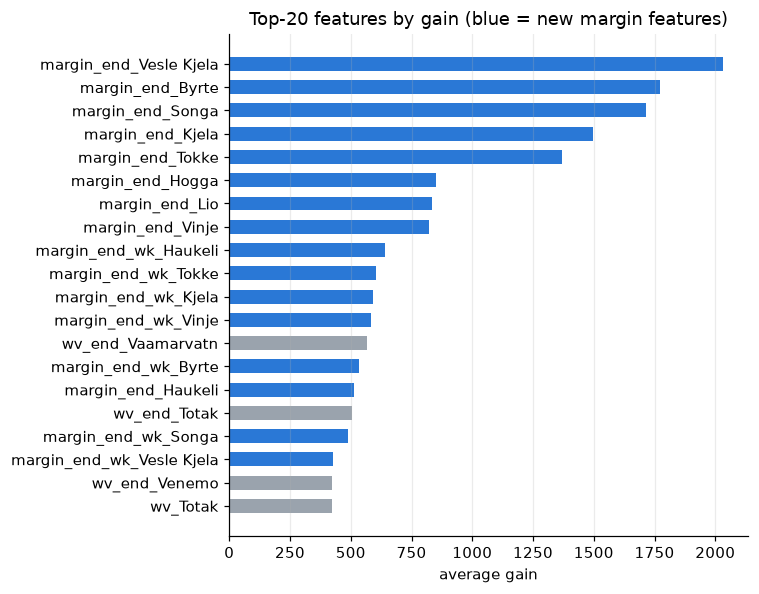

In [7]:
imp = pd.Series(res["model"].get_booster().get_score(importance_type="gain")).sort_values().tail(20)
colors = [BLUE if c.startswith("margin") else "#9aa3ad" for c in imp.index]
fig, ax = plt.subplots(figsize=(7, 5.5))
ax.barh(imp.index, imp.values, color=colors, height=0.6)
ax.set_xlabel("average gain"); ax.set_title("Top-20 features by gain (blue = new margin features)")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

## 4. Refit on all years and write the submission

In [8]:
t0 = time.time()
final_model = xgb.XGBClassifier(n_estimators=res["n_rounds"], tree_method="hist", device=DEVICE, random_state=SEED, **params).fit(X, Y)
print(f"refit on {len(uc)} cases with {res['n_rounds']} rounds in {time.time() - t0:.0f}s")

X_test = add_margin_features(build_base(test_map["starttime"]))
submission = to_wide(final_model.predict_proba(X_test), test_map["Run No"])
assert list(submission.columns) == list(sample.columns)
vals = submission[label_cols].to_numpy()
assert ((vals >= 0) & (vals <= 1)).all()

fname = f"submission_xgb_margin_cv{res['report_auc']:.4f}.csv"
submission.to_csv(fname, index=False)
print("saved", fname, submission.shape)

refit on 2922 cases with 222 rounds in 84s


saved submission_xgb_margin_cv0.9786.csv (725, 2353)
